In [5]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
test_path = "../../Dataset/processed/test_data.csv"
test_data = pd.read_csv(test_path)

print("Test data loaded successfully")
print("Shape: ", test_data.shape)

Test data loaded successfully
Shape:  (340, 2461)


In [3]:
X_test = test_data.drop(columns=["Revenue(INR)"])
y_test = test_data["Revenue(INR)"]

print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

X_test shape:  (340, 2460)
y_test shape:  (340,)


In [6]:
model_path = "../models/elastic_net_model.pkl"
model = joblib.load(model_path)

print("Elastic Net Model loaded successfully")

Elastic Net Model loaded successfully


In [7]:
y_pred = model.predict(X_test)

print("Predictions generated successfully")
print("Number of predictions: ", len(y_pred))

Predictions generated successfully
Number of predictions:  340


In [8]:
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error (MAE):", mae)

Mean Absolute Error (MAE): 66956283.08245439


In [9]:
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error (MSE):", mse)

Mean Squared Error (MSE): 1.2780370698296384e+16


In [10]:
rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)

Root Mean Squared Error (RMSE): 113050301.62850687


In [12]:
r2 = r2_score(y_test, y_pred)
print("R2 Score: ", r2)

R2 Score:  0.7936998811005649


In [15]:
evaluation_results = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R²"
    ],
    "Value": [
        mae,
        mse,
        rmse,
        r2
    ]
})

print(evaluation_results)

  Metric         Value
0    MAE  6.695628e+07
1    MSE  1.278037e+16
2   RMSE  1.130503e+08
3     R²  7.936999e-01


In [16]:
print("====================================")
print("MODEL EVALUATION RESULTS")
print("====================================")

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

MODEL EVALUATION RESULTS
MAE : 66956283.08
MSE : 1.2780370698296384e+16
RMSE: 113050301.63
R²  : 0.7937


In [17]:
comparison = pd.DataFrame({
    "Actual Revenue": y_test.values,
    "Predicted Revenue": y_pred
})

comparison["Error"] = (
    comparison["Actual Revenue"] -
    comparison["Predicted Revenue"]
)

comparison.head(10)

,Actual Revenue,Predicted Revenue,Error
0,230000000.0,3.125818e+08,-8.258184e+07
1,350000000.0,3.413746e+08,8.625407e+06
2,80000000.0,-3.377649e+07,1.137765e+08
3,160000000.0,1.000698e+08,5.993021e+07
4,20000000.0,5.067319e+07,-3.067319e+07
5,70000000.0,-2.303645e+07,9.303645e+07
6,3000000.0,7.167496e+06,-4.167496e+06
7,20000000.0,4.741470e+07,-2.741470e+07
8,190000000.0,4.400744e+08,-2.500744e+08
9,80000000.0,4.895662e+07,3.104338e+07


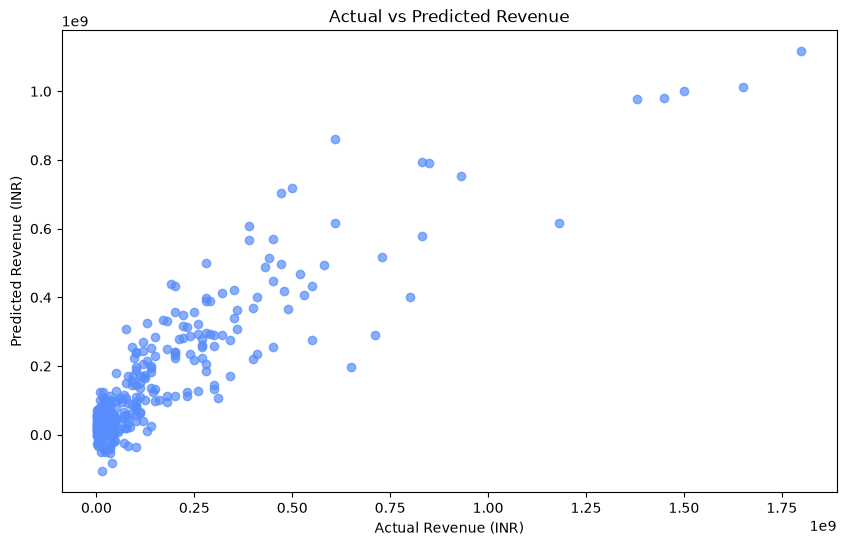

In [18]:
plt.figure(figsize=(10, 6))

plt.scatter(
    comparison["Actual Revenue"],
    comparison["Predicted Revenue"],
    alpha=0.7
)

plt.savefig(
    "../output/plots/15.png"
)

plt.xlabel("Actual Revenue (INR)")
plt.ylabel("Predicted Revenue (INR)")
plt.title("Actual vs Predicted Revenue")

plt.show()

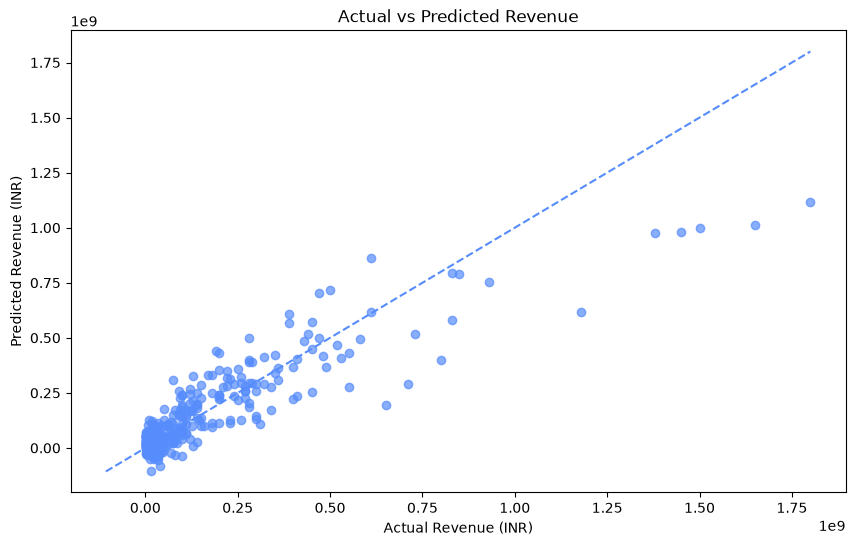

In [19]:
plt.figure(figsize=(10, 6))

plt.scatter(
    comparison["Actual Revenue"],
    comparison["Predicted Revenue"],
    alpha=0.7
)

minimum_value = min(
    comparison["Actual Revenue"].min(),
    comparison["Predicted Revenue"].min()
)

maximum_value = max(
    comparison["Actual Revenue"].max(),
    comparison["Predicted Revenue"].max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("Actual Revenue (INR)")
plt.ylabel("Predicted Revenue (INR)")
plt.title("Actual vs Predicted Revenue")

plt.show()

In [20]:
residuals = y_test - y_pred

print("Residual statistics:")
print(residuals.describe())

Residual statistics:
count    3.400000e+02
mean     1.625092e+06
std      1.132052e+08
min     -2.502993e+08
25%     -4.802661e+07
50%     -1.215298e+07
75%      2.748250e+07
max      6.841374e+08
Name: Revenue(INR), dtype: float64


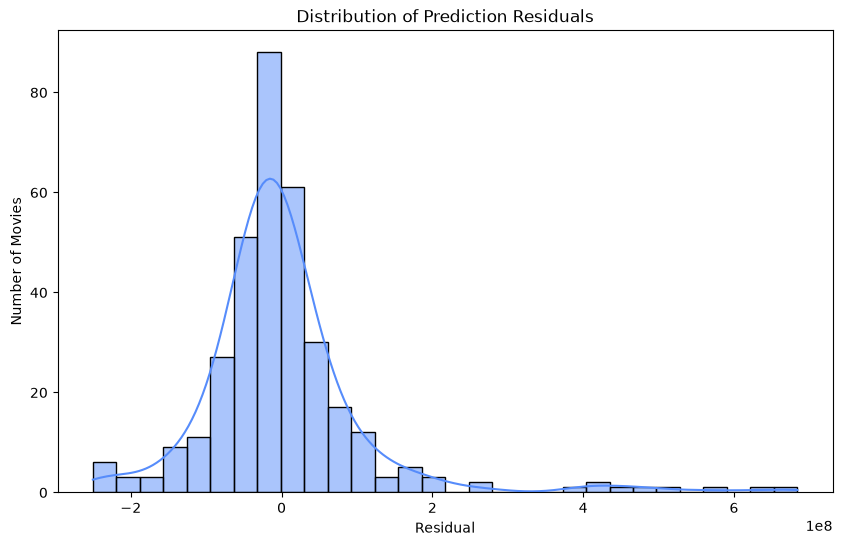

In [21]:
plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.xlabel("Residual")
plt.ylabel("Number of Movies")
plt.title("Distribution of Prediction Residuals")

plt.show()

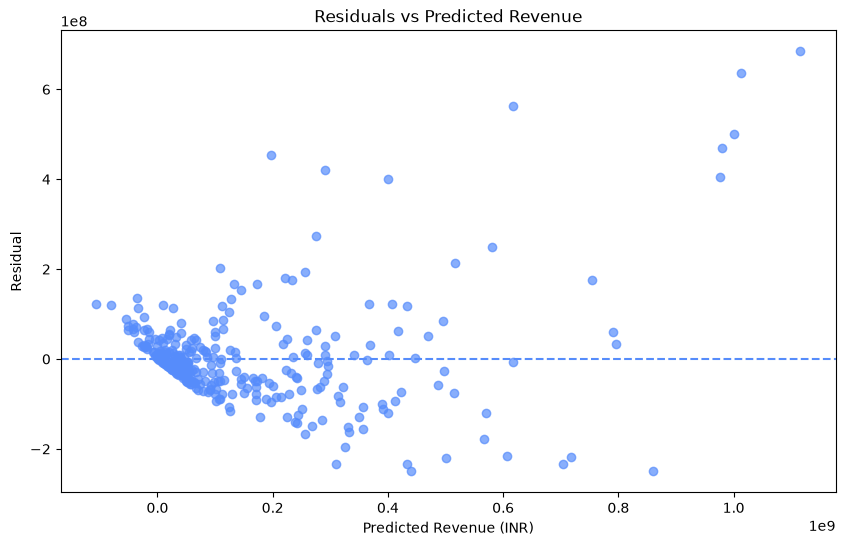

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Revenue (INR)")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Revenue")

plt.show()

In [23]:
comparison["Absolute Error"] = (
    comparison["Actual Revenue"] -
    comparison["Predicted Revenue"]
).abs()

comparison.head(10)

,Actual Revenue,Predicted Revenue,Error,Absolute Error
0,230000000.0,3.125818e+08,-8.258184e+07,8.258184e+07
1,350000000.0,3.413746e+08,8.625407e+06,8.625407e+06
2,80000000.0,-3.377649e+07,1.137765e+08,1.137765e+08
3,160000000.0,1.000698e+08,5.993021e+07,5.993021e+07
4,20000000.0,5.067319e+07,-3.067319e+07,3.067319e+07
5,70000000.0,-2.303645e+07,9.303645e+07,9.303645e+07
6,3000000.0,7.167496e+06,-4.167496e+06,4.167496e+06
7,20000000.0,4.741470e+07,-2.741470e+07,2.741470e+07
8,190000000.0,4.400744e+08,-2.500744e+08,2.500744e+08
9,80000000.0,4.895662e+07,3.104338e+07,3.104338e+07


In [24]:
largest_errors = comparison.sort_values(
    by="Absolute Error",
    ascending=False
)

largest_errors.head(10)

,Actual Revenue,Predicted Revenue,Error,Absolute Error
200,1.800000e+09,1.115863e+09,6.841374e+08,6.841374e+08
101,1.650000e+09,1.013189e+09,6.368107e+08,6.368107e+08
96,1.180000e+09,6.167199e+08,5.632801e+08,5.632801e+08
54,1.500000e+09,9.998121e+08,5.001879e+08,5.001879e+08
277,1.450000e+09,9.806663e+08,4.693337e+08,4.693337e+08
175,6.500000e+08,1.969324e+08,4.530676e+08,4.530676e+08
49,7.100000e+08,2.903743e+08,4.196257e+08,4.196257e+08
60,1.380000e+09,9.761827e+08,4.038173e+08,4.038173e+08
222,8.000000e+08,3.997277e+08,4.002723e+08,4.002723e+08
59,5.500000e+08,2.759505e+08,2.740495e+08,2.740495e+08


In [26]:
evaluation_results.to_csv(
    "../../Dataset/processed/model_evaluation.csv",
    index=False
)

print("Evaluation results saved successfully")

Evaluation results saved successfully


In [27]:
comparison.to_csv(
    "../../Dataset/processed/model_predictions.csv",
    index=False
)

print("Prediction results saved successfully")

Prediction results saved successfully
